# EMQA_L1_hydro_case

**Case study: Romanian hydro output, wet 2023 vs dry 2025, and hydro vs the day-ahead price**

Energy Markets Quantitative Analysis (EMQA), Lecture 1 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L1/EMQA_L1_hydro_case/EMQA_L1_hydro_case.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Monthly Romanian hydro generation (TWh) in the wet year 2023, the dry year 2025 and the 2015-2025 monthly mean, and a scatter of monthly hydro output against the monthly mean Romanian day-ahead price; prints the annual totals, net imports and the hydro coefficient of a regression of the price on hydro and TTF gas (HAC standard errors).

**Data:** monthly, 2015-01 to 2025-12. **Source:** energy-charts.info (Fraunhofer ISE); ENTSO-E (Transelectrica data for Romania).

The numbers printed below are those on the slide; the tag `[key]` is their name in `lectures/L1/L1_numbers.json`.

In [2]:
import json
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}   # fixed colour per bidding zone
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZONES = ['RO', 'BG', 'HU', 'DE_LU']
ZONE_NAME = {'RO': 'Romania (OPCOM PZU)', 'BG': 'Bulgaria (IBEX)', 'HU': 'Hungary (HUPX)', 'DE_LU': 'Germany-Luxembourg'}
MON_EN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
MON1 = ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D']


def legend_bottom(fig, ncol=4, y=0.0):
    """One legend centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l_ in zip(*ax.get_legend_handles_labels()):
            if l_ not in labels:
                handles.append(h)
                labels.append(l_)
    if handles:
        fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
                   handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Round as on the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def d(ts):
    return pd.Timestamp(ts).strftime('%Y-%m-%d')


def show(key, label, value):
    """Print a number of the slide; [key] = its name in lectures/L1/L1_numbers.json."""
    print(f'{label} = {value}   [{key}]')

## Data
Real series from the course repository (see `data/SOURCES.md`), cut at the last complete month; missing values stay missing.

In [3]:
# data cut-off: last complete calendar month common to the Romanian prices and the generation data
_p = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')['RO']
_g = pd.read_csv(DATA + 'generation_ro_mw_daily_cet.csv', usecols=['date_cet', 'hydro_run_of_river'],
                 parse_dates=['date_cet']).set_index('date_cet')['hydro_run_of_river']
_last = min(_p.dropna().index.max(), _g.dropna().index.max())
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
END_UTC = (END + pd.Timedelta(days=1)).tz_localize('Europe/Brussels').tz_convert('UTC')   # end of the CET day, in UTC
Y = END.year
print('data cut-off:', END.date())

# Romanian generation by source and load, hourly mean MW (UTC, interval start)
GH = pd.read_csv(DATA + 'generation_ro_mw_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
GH = GH.loc[GH.index < END_UTC]
# Romanian cross-border physical flows, daily mean MW (sum > 0 = net import)
CB = pd.read_csv(DATA + 'crossborder_ro_mw_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet').loc[:END]
# daily base prices (mean of all market time units of the CET/CEST day), EUR/MWh
P = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet').loc[:END]
# TTF natural gas, monthly mean in EUR/MWh (World Bank)
TTF = pd.read_csv(DATA + 'ttf_monthly.csv')
TTF.index = pd.PeriodIndex(TTF['month'], freq='M').to_timestamp()
TTF = TTF.drop(columns='month').loc[:END]

data cut-off: 2026-10-31


## Computation

In [4]:
import statsmodels.api as sm
hyd = GH[['hydro_run_of_river', 'hydro_water_reservoir']].sum(axis=1, min_count=2)
hy_a = hyd.groupby(GH.index.year).sum() / 1e6                                   # TWh per year, reported hours
hydro_m = hyd.resample('MS').sum(min_count=600) / 1e6                          # TWh per month (>= 600 reported hours)
hydro_m.index = hydro_m.index.tz_localize(None)
hydro_m = hydro_m.loc[:str(Y - 1)].dropna()
imp_twh = (CB['sum'] * 24 / 1e6).groupby(CB.index.year).sum()                   # net imports, TWh
dfm = pd.concat([hydro_m.rename('hydro'), P['RO'].resample('MS').mean().rename('price'),
                 TTF['ttf_eur_mwh'].rename('ttf')], axis=1).dropna()
ols = sm.OLS(dfm['price'], sm.add_constant(dfm[['hydro', 'ttf']])).fit(cov_type='HAC', cov_kwds={'maxlags': 6})
show('hydro.y2023', 'hydro 2023, TWh', fl(hy_a.loc[2023], 2))
show('hydro.y2025', 'hydro 2025, TWh', fl(hy_a.loc[2025], 2))
show('hydro.chg_pct', 'change 2025 vs 2023, %', fl((hy_a.loc[2025] / hy_a.loc[2023] - 1) * 100, 1))
show('hydro.mean_1525', 'mean 2015-2025, TWh', fl(hy_a.loc[2015:2025].mean(), 2))
show('hydro.vs_mean_pct', '2025 vs the 2015-2025 mean, %', fl((hy_a.loc[2025] / hy_a.loc[2015:2025].mean() - 1) * 100, 1))
show('hydro.netimp2023', 'net imports 2023, TWh', fl(imp_twh.loc[2023], 2))
show('hydro.netimp2025', 'net imports 2025, TWh', fl(imp_twh.loc[2025], 2))
show('hydro.reg.n', 'regression: months', int(ols.nobs))
show('hydro.reg.r2', 'regression: R squared', fl(ols.rsquared, 3))
show('hydro.reg.hydro.b', 'regression: EUR/MWh per extra TWh of hydro', fl(ols.params['hydro'], 2))
show('hydro.reg.hydro.t', 'regression: t statistic (HAC)', fl(ols.tvalues['hydro'], 2))

hydro 2023, TWh = 18.34   [hydro.y2023]
hydro 2025, TWh = 12.15   [hydro.y2025]
change 2025 vs 2023, % = -33.8   [hydro.chg_pct]
mean 2015-2025, TWh = 15.85   [hydro.mean_1525]
2025 vs the 2015-2025 mean, % = -23.3   [hydro.vs_mean_pct]
net imports 2023, TWh = -3.06   [hydro.netimp2023]
net imports 2025, TWh = 3.76   [hydro.netimp2025]
regression: months = 132   [hydro.reg.n]
regression: R squared = 0.941   [hydro.reg.r2]
regression: EUR/MWh per extra TWh of hydro = -19.55   [hydro.reg.hydro.b]
regression: t statistic (HAC) = -2.78   [hydro.reg.hydro.t]


## Chart

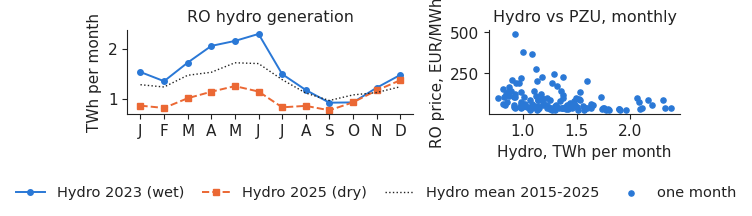

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.2), gridspec_kw={'width_ratios': [1.5, 1]})
hy_avg = hydro_m.loc['2015':'2025'].groupby(hydro_m.loc['2015':'2025'].index.month).mean()
axs[0].plot(range(1, 13), hydro_m.loc['2023'].values, color=PAL['RO'], marker='o', ms=4, label='Hydro 2023 (wet)')
axs[0].plot(range(1, 13), hydro_m.loc['2025'].values, color=PAL['DE_LU'], marker='s', ms=4, ls='--', label='Hydro 2025 (dry)')
axs[0].plot(range(1, 13), hy_avg.values, color='#222222', lw=1.0, ls=':', label='Hydro mean 2015-2025')
axs[0].set_xticks(range(1, 13))
axs[0].set_xticklabels(MON1)
axs[0].set_ylabel('TWh per month')
axs[0].set_title('RO hydro generation')
axs[1].scatter(dfm['hydro'], dfm['price'], s=14, color=PAL['RO'], label='one month')
axs[1].set_xlabel('Hydro, TWh per month')
axs[1].set_ylabel('RO price, EUR/MWh')
axs[1].set_title('Hydro vs PZU, monthly')
legend_bottom(fig, ncol=4)
fig.tight_layout(rect=(0, 0.17, 1, 1))
plt.savefig('hydro_case.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()